In [7]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import torch
from torch_geometric.datasets import GraphLandDataset
from torch_geometric.utils import homophily, degree 

ROOT_DIR = '../data'
data_rl = GraphLandDataset(root=ROOT_DIR, name='tolokers-2', split='RL')[0]
data_rh = GraphLandDataset(root=ROOT_DIR, name='tolokers-2', split='RH')[0]
data_th = GraphLandDataset(root=ROOT_DIR, name='tolokers-2', split='TH')[0]

In [8]:
rows = []
for mode_name, data in [('RL', data_rl), ('RH', data_rh), ('TH', data_th)]:
    for split_name, mask in [('train', data.train_mask),
                             ('val', data.val_mask),
                             ('test', data.test_mask)]:
        y_split = data.y[mask]
        n_pos = (y_split == 1).sum().item()
        n_neg = (y_split == 0).sum().item()
        total = n_pos + n_neg
        rows.append({
            'mode': mode_name,
            'split': split_name,
            'n_total': total,
            'n_pos': n_pos,
            'n_neg': n_neg,
            'prevalence': n_pos / total if total > 0 else 0.0
        })

df_balance = pd.DataFrame(rows)
print(df_balance.to_string(index=False))

mode split  n_total  n_pos  n_neg  prevalence
  RL train     1175    256    919    0.217872
  RL   val     1176    257    919    0.218537
  RL  test     9407   2053   7354    0.218242
  RH train     5831   1273   4558    0.218316
  RH   val     2953    644   2309    0.218083
  RH  test     2974    649   2325    0.218225
  TH train     5831   2074   3757    0.355685
  TH   val     2953    236   2717    0.079919
  TH  test     2974    256   2718    0.086079


In [9]:
homo_rows = []
for mode_name, data in [('RL', data_rl), ('RH', data_rh), ('TH', data_th)]:
    ei = data.edge_index
    y = data.y
    train_mask = data.train_mask
    # фильтруем рёбра: оба конца в train
    edge_mask = train_mask[ei[0]] & train_mask[ei[1]]
    ei_train = ei[:, edge_mask]
    if ei_train.numel() == 0:
        h = float('nan')
    else:
        # homophily(method='edge') считает долю рёбер с одинаковыми метками
        h = homophily(ei_train, y, method='edge')
    homo_rows.append({'mode': mode_name, 'edge_homophily_train': h})
    print(f"{mode_name}: edge homophily (train) = {h:.4f}")

RL: edge homophily (train) = 0.6021
RH: edge homophily (train) = 0.5936
TH: edge homophily (train) = 0.4989


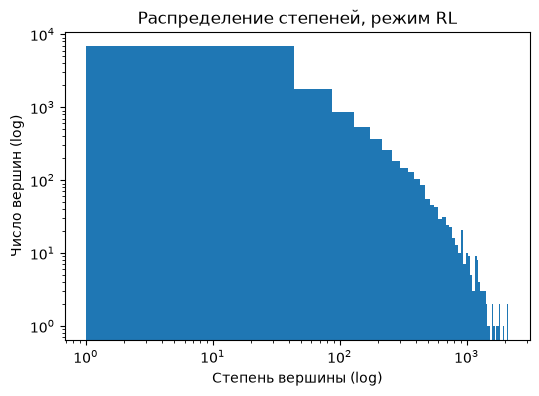

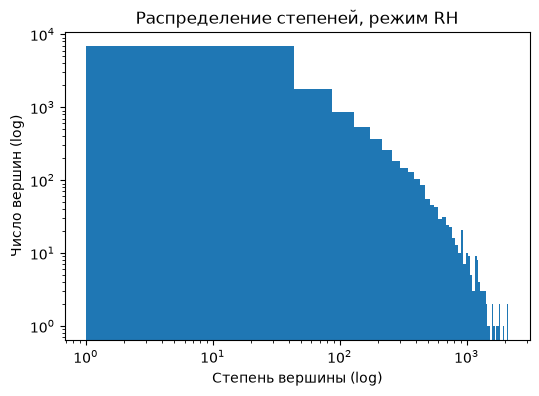

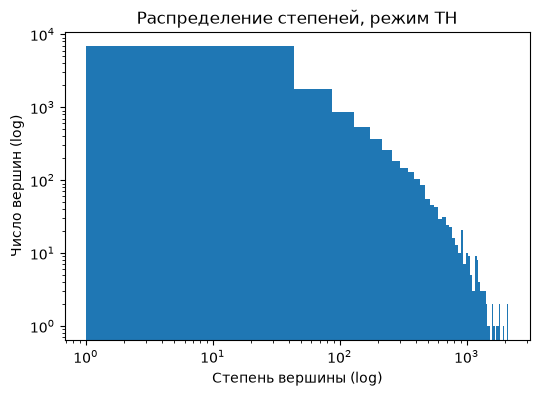

In [10]:
deg_rows = []
for mode_name, data in [('RL', data_rl), ('RH', data_rh), ('TH', data_th)]:
    # degree возвращает степень для каждой вершины (учитывая неориентированность)
    deg = degree(data.edge_index[0], num_nodes=data.num_nodes,
                 dtype=torch.long).numpy()
    deg_rows.append({
        'mode': mode_name,
        'mean_degree': deg.mean(),
        'median_degree': np.median(deg),
        'max_degree': deg.max(),
        'n_isolated': (deg == 0).sum(),
        'n_hubs_gt_100': (deg > 100).sum()
    })

    # Гистограмма степеней (log-scale по x и y, чтобы видеть хвост)
    plt.figure(figsize=(6, 4))
    plt.hist(deg, bins=50)
    plt.xscale('log')
    plt.yscale('log')
    plt.xlabel('Степень вершины (log)')
    plt.ylabel('Число вершин (log)')
    plt.title(f'Распределение степеней, режим {mode_name}')
    plt.show()

Text(0.5, 1.0, 'TH: prevalence по временным сплитам')

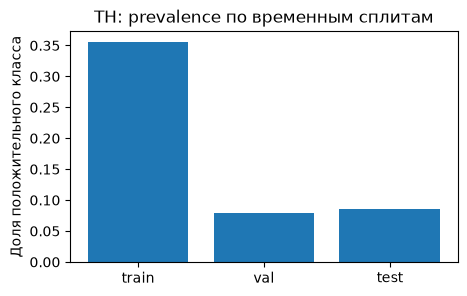

In [11]:
th_bal = df_balance[df_balance['mode'] == 'TH']
plt.figure(figsize=(5, 3))
plt.bar(th_bal['split'], th_bal['prevalence'])
plt.ylabel('Доля положительного класса')
plt.title('TH: prevalence по временным сплитам')

Text(0.5, 0.98, 'Сдвиг распределения признаков: RH train vs TH test')

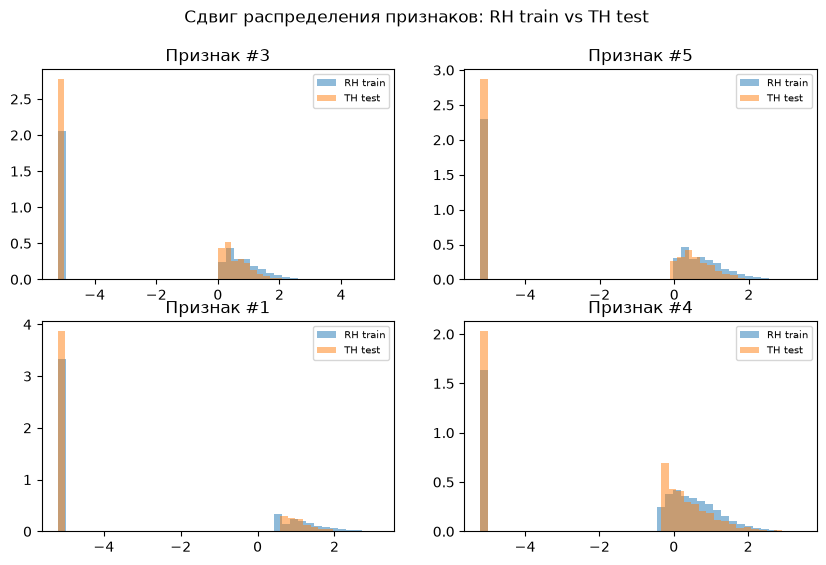

In [12]:
x_rh = data_rh.x.numpy()
train_mask_rh = data_rh.train_mask.numpy()
variances = x_rh[train_mask_rh].var(axis=0)
top_features = np.argsort(variances)[-4:][::-1]

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, feat_idx in zip(axes.ravel(), top_features):
    # RH train
    ax.hist(x_rh[train_mask_rh][:, feat_idx], bins=40, alpha=0.5,
            label='RH train', density=True)
    # TH test
    x_th = data_th.x.numpy()
    test_mask_th = data_th.test_mask.numpy()
    ax.hist(x_th[test_mask_th][:, feat_idx], bins=40, alpha=0.5,
            label='TH test', density=True)
    ax.set_title(f'Признак #{feat_idx}')
    ax.legend(fontsize=7)
plt.suptitle('Сдвиг распределения признаков: RH train vs TH test')